In [1]:
# ==============================================================
# Simulação Rocketpy - Merak
# Desenvolvido por: Guilherme Cintra, Jean Lucas Alves e Maria Luiza Caroneze
# ==============================================================

## Bibliotecas

In [2]:
from rocketpy import Environment, SolidMotor, Rocket, Flight, Function, MonteCarlo
import numpy as np
import datetime
import os
import pandas as pd
import datetime
from rocketpy.stochastic import (
    StochasticEnvironment,
    StochasticFlight,
    StochasticNoseCone,
    StochasticParachute,
    StochasticRailButtons,
    StochasticRocket,
    StochasticSolidMotor,
    StochasticTail,
    StochasticTrapezoidalFins,
)

## Parâmetros da simulação de Monte Carlo


In [3]:
# Os parâmetros nominais do Merak (massa, inércia, motor, aerodinâmica,
# posições, paraquedas etc.) são definidos diretamente nas células do
# Motor, do Foguete e do Voo, mais abaixo neste notebook.
#
# As incertezas (desvios padrão) usadas na simulação de Monte Carlo ficam
# centralizadas na seção "Simulação de Monte Carlo" (variáveis dp_...),
# aplicadas em cima dos valores reais do Merak já definidos acima.

## Setup de gráficos

In [4]:
%config InlineBackend.figure_formats = ['svg']
import matplotlib as mpl
import matplotlib.pyplot as plt

%matplotlib inline
mpl.rcParams["figure.figsize"] = [8, 5]
mpl.rcParams["figure.dpi"] = 120
mpl.rcParams["font.size"] = 14
mpl.rcParams["legend.fontsize"] = 14
mpl.rcParams["figure.titlesize"] = 14

## Configurações do Ambiente

In [5]:

env = Environment(latitude=-21.943053, longitude=-48.954086, elevation=480)


ano  = 2026
mes  = 9
dia  = 3
hora = 14

env.set_date(datetime.datetime(ano, mes, dia, hora))

In [7]:
import numpy as np
from rocketpy import Environment

def configurar_atmosfera(env, escolha="GFS", incluir_rajadas=False):
    
    # --- Função Auxiliar de Rajada ---
    def calcular_rajada(h):
        """Retorna 15.0 m/s dentro de uma janela de 20m a cada 100m, caso contrário 0.0."""
        resto = h % 100
        return 60 if (resto < 10 or resto > 90) else 0.0

    # --- Configuração GFS ---
    if escolha == "GFS":
        env.set_atmospheric_model(type="Forecast", file="GFS")

  
        if incluir_rajadas:
            # Pega a altitude máxima da matriz
            alt_max = pressao_corrigida[-1, 0]
            
            altitudes = np.arange(0, alt_max, 10) 
            
            # Avalia o vento X do GFS em cada altitude e soma com a rajada
            vento_x_corrigido = [
                [h, env.wind_velocity_x(h) + calcular_rajada(h)] for h in altitudes
            ]
            env.wind_velocity_x.set_source(vento_x_corrigido)
            print("Atmosfera configurada: Modelo GFS corrigido + Rajadas ativadas.")
        else:
            print("Atmosfera configurada: Modelo GFS com escala corrigida (Sem rajadas).")

    # --- Configuração VENTO 10 m/s ---
    elif escolha == "VENTO_10":
        if incluir_rajadas:
        
            wind_x = lambda h: 10.0 + calcular_rajada(h)
            print("Atmosfera configurada: Vento de 10 m/s + Rajadas ativadas.")
        else:
            wind_x = 10.0
            print("Atmosfera configurada: Atmosfera Padrão + Vento constante de 10 m/s.")
            
        env.set_atmospheric_model(type="custom_atmosphere", wind_u=wind_x, wind_v=0.0)

    # --- Configuração VENTO 3 m/s ---
    elif escolha == "VENTO_3":
        if incluir_rajadas:
            wind_x = lambda h: 3.0 + calcular_rajada(h)
            print("Atmosfera configurada: Vento de 3 m/s + Rajadas ativadas.")
        else:
            wind_x = 3.0
            print("Atmosfera configurada: Atmosfera Padrão + Vento constante de 3 m/s.")
            
        env.set_atmospheric_model(type="custom_atmosphere", wind_u=wind_x, wind_v=0.0)

    else:
        raise ValueError("Opção inválida. Escolha entre 'GFS', 'VENTO_10' ou 'VENTO_3'.")

    return env




# 1. Defina o perfil base ("GFS", "VENTO_10" ou "VENTO_3")
opcao_desejada = "VENTO_3" 

# 2. Defina se as rajadas a cada 100m estão ligadas (True) ou desligadas (False)
com_rajadas = False


# 3. Aplique a configuração ao ambiente
env = configurar_atmosfera(env, escolha=opcao_desejada, incluir_rajadas=com_rajadas)

Atmosfera configurada: Atmosfera Padrão + Vento constante de 3 m/s.



Gravity Details

Acceleration of gravity at surface level:    9.7861 m/s²
Acceleration of gravity at  80.000 km (ASL): 9.5452 m/s²


Launch Site Details

Launch Date: 2026-09-03 14:00:00 UTC
Launch Site Latitude: -21.94305°
Launch Site Longitude: -48.95409°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 91457.83 W    7568202.61 S
Launch Site UTM zone: 23K
Launch Site Surface Elevation: 480.0 m


Atmospheric Model Details

Atmospheric Model Type: custom_atmosphere
custom_atmosphere Maximum Height: 80.000 km

Surface Atmospheric Conditions

Surface Wind Speed: 3.00 m/s
Surface Wind Direction: 270.00°
Surface Wind Heading: 90.00°
Surface Pressure: 957.20 hPa
Surface Temperature: 285.04 K
Surface Air Density: 1.170 kg/m³
Surface Speed of Sound: 338.32 m/s


Earth Model Details

Earth Radius at Launch site: 6375.17 km
Semi-major Axis: 6378.14 km
Semi-minor Axis: 6356.75 km
Flattening: 0.0034


Atmospheric Model Plots



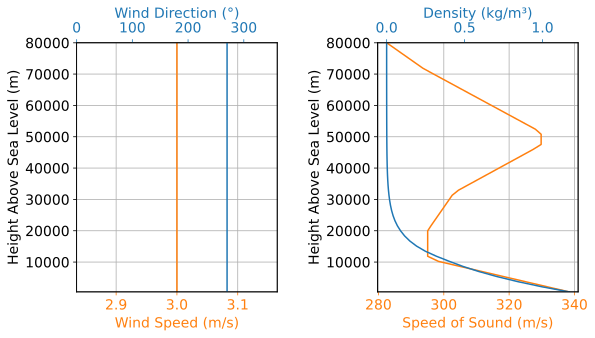

In [8]:
env.info()

## Motor

In [9]:

MOTOR_FILE = "REAL.eng"

ConstanteDeslocamento = 19 / 1000   # metros

Motor = SolidMotor(
    thrust_source                  = MOTOR_FILE,
    dry_mass                       = 1.850,
    dry_inertia                    = (0.065, 0.065, 0.002),
    nozzle_radius                  = 18.03 / 1000,
    grain_number                   = 5,
    grain_density                  = 1841,
    grain_outer_radius             = 28.52  / 1000,
    grain_initial_inner_radius     = 17   / 1000,
    grain_initial_height           = 70   / 1000,
    grain_separation               = 1    / 1000,
    grains_center_of_mass_position = 0.24632,
    center_of_dry_mass_position    = 0.2685,
    nozzle_position                = ConstanteDeslocamento,
    burn_time                      = 2.0994,
    throat_radius                  = 7.5  / 1000,
    coordinate_system_orientation  = "nozzle_to_combustion_chamber",
)

Nozzle Details
Nozzle Radius: 0.01803 m
Nozzle Throat Radius: 0.0075 m

Grain Details
Number of Grains: 5
Grain Spacing: 0.001 m
Grain Density: 1841 kg/m3
Grain Outer Radius: 0.02852 m
Grain Inner Radius: 0.017 m
Grain Height: 0.07 m
Grain Volume: 0.000 m3
Grain Mass: 0.212 kg

Motor Details
Total Burning Time: 2.0994 s
Total Propellant Mass: 1.062 kg
Structural Mass Ratio: 0.635
Average Propellant Exhaust Velocity: 1235.011 m/s
Average Thrust: 624.456 N
Maximum Thrust: 2026.885712 N at 0.938 s after ignition.
Total Impulse: 1310.984 Ns



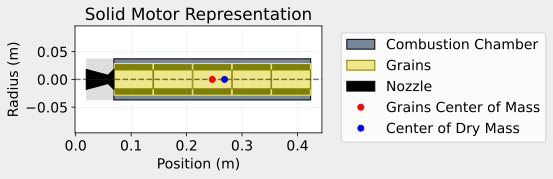

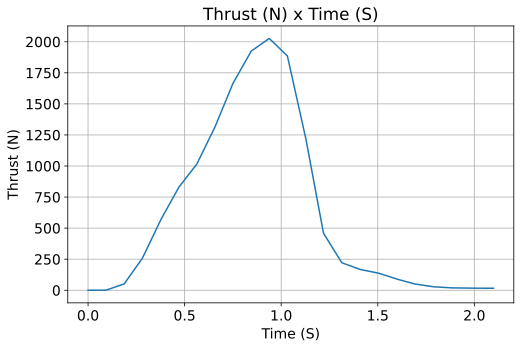

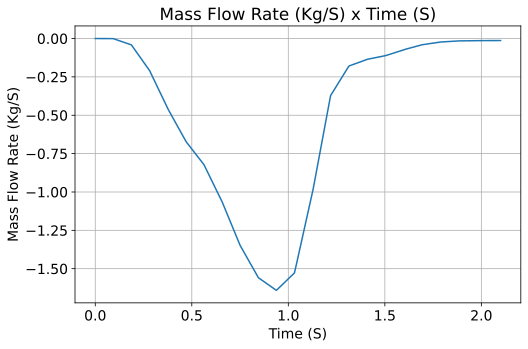

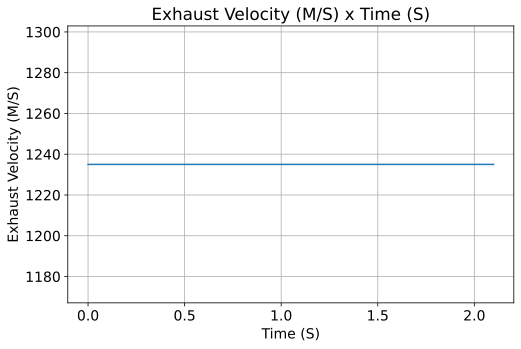

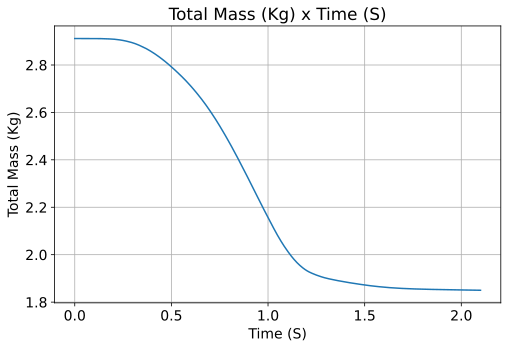

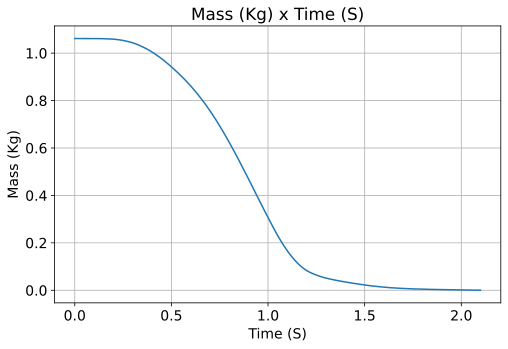

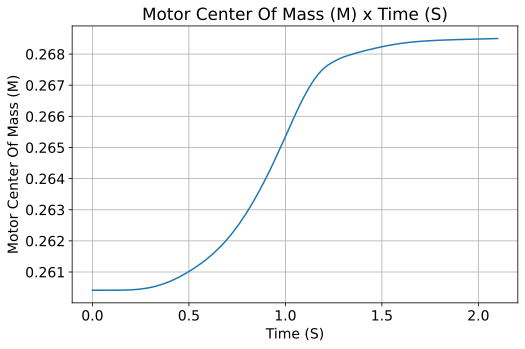

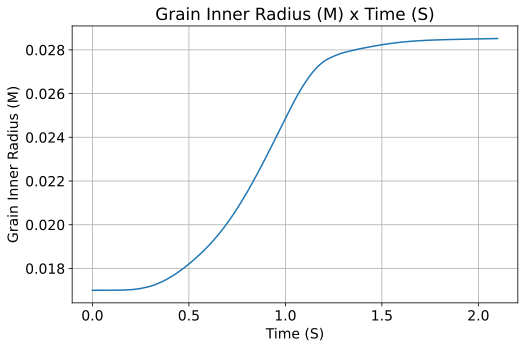

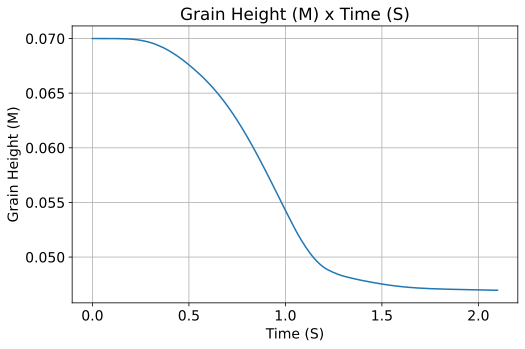

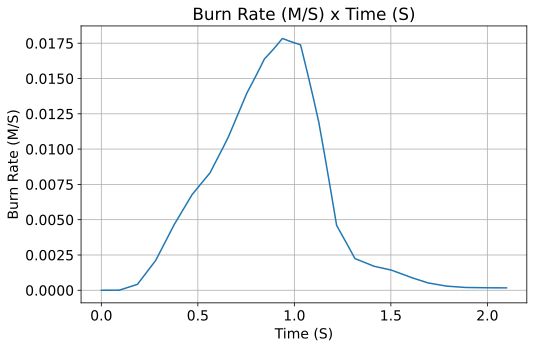

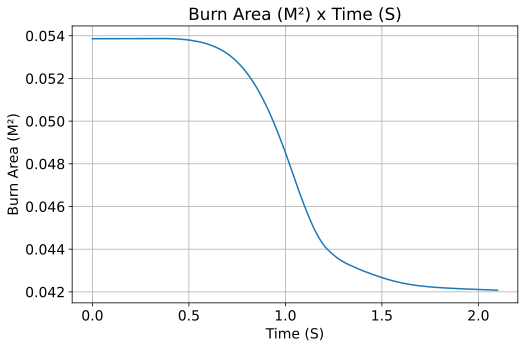

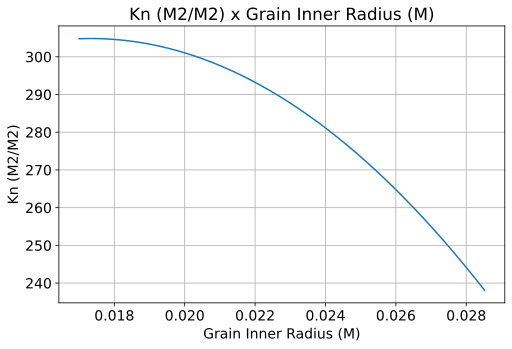

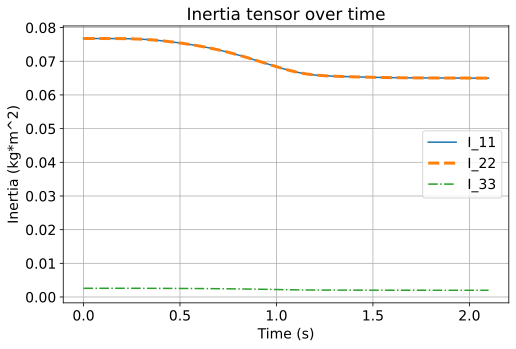

In [10]:
Motor.all_info()

## Foguete

In [11]:
df_rasaero = pd.read_csv("MerakCD_corrigido.csv", sep=",", on_bad_lines='skip', engine='python')


df_filtrado = df_rasaero[df_rasaero["Alpha"] == 0].iloc[:, [0, 3, 4]].dropna()


df_filtrado = df_filtrado.drop_duplicates(subset=df_filtrado.columns[0]).sort_values(df_filtrado.columns[0])

curva_off = list(df_filtrado.iloc[:, [0, 1]].itertuples(index=False, name=None))
curva_on = list(df_filtrado.iloc[:, [0, 2]].itertuples(index=False, name=None))

merak = Rocket(
    radius=0.0802 / 2,  
    mass=4.457,         
    inertia=(0.724 , 0.724 , 0.012),
    center_of_mass_without_motor=0.77513,
    coordinate_system_orientation="tail_to_nose",
    
    power_off_drag=curva_off,
    power_on_drag=curva_on
)


In [12]:
merak.add_motor(Motor, position=-ConstanteDeslocamento)

In [13]:
POS_RAIL_UPPER = 1.020
POS_RAIL_LOWER = 0.460
ANGULO_RAIL_BUTTONS = 45

rail_buttons = merak.set_rail_buttons(
    upper_button_position = POS_RAIL_UPPER,
    lower_button_position = POS_RAIL_LOWER,
    angular_position      = ANGULO_RAIL_BUTTONS,
)


In [14]:
POS_NOSE = 1.68330

nose_cone = merak.add_nose(
    length   = 0.16,
    kind     = "elliptical",
    position = POS_NOSE,
)


## Aletas

> **Airfoil:** O perfil NACA0012 é opcional. Se não tiver o arquivo `.txt`, a célula abaixo usa aletas sem perfil.
> Coloque o arquivo `NACA0012-radians.txt` na mesma pasta do notebook e ajuste o caminho se necessário.

In [15]:

AIRFOIL_FILE = "NACA0012-radians.txt"   

airfoil_arg = (AIRFOIL_FILE, "radians") if (AIRFOIL_FILE and os.path.isfile(AIRFOIL_FILE)) else None

POS_FINS = 0.064 + 0.305

fin_set = merak.add_trapezoidal_fins(
    n            = 4,
    root_chord   = 0.305,
    tip_chord    = 0.15,
    span         = 0.148,
    position     = POS_FINS,
    cant_angle   = 0,
    sweep_length = 0.082,
    airfoil      = airfoil_arg,
)


## Boattail

In [16]:
POS_TAIL = 0.0433

tail = merak.add_tail(
    top_radius    = 0.0802 / 2,
    bottom_radius = 0.064  / 2,
    length        = 0.046,
    position      = POS_TAIL,
)


## Paraquedas


In [17]:
merak.parachutes.clear()

def gatilho_apogeu(pressao, altura, y, *args):
    return y[5] < 0  

# 3. Adiciona o paraquedas
main = merak.add_parachute(
    name          = "main",
    cd_s          = 1.5 * 3.295,
    trigger       = gatilho_apogeu,
    sampling_rate = 105,
    lag           = 2,               
    noise         = (0, 0, 0),
    radius        = 1.621,
    height        = 1.051,
    porosity      = 0.0432,
)

## Visualização

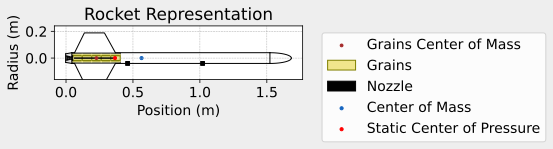

In [18]:
merak.draw()

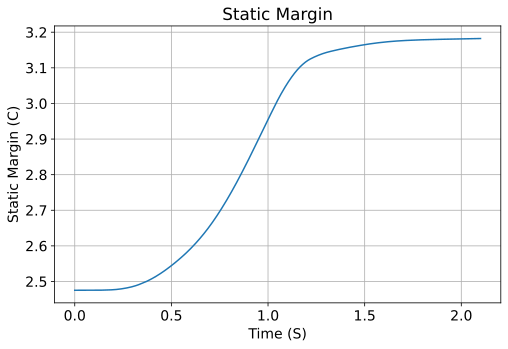

In [19]:
merak.plots.static_margin()

## Simulação de Voo

In [20]:
test_flight = Flight(
    rocket      = merak,
    environment = env,
    rail_length = 4,
    inclination = 80,
    heading     = 0,
)



Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 480.00 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 0.920 | e1: -0.081 | e2: 0.033 | e3: 0.381
Euler Angles - Spin φ : 45.00° | Nutation θ: -10.00° | Precession ψ: -0.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: 2.475 c


Surface Wind Conditions

Frontal Surface Wind Speed: 0.00 m/s
Lateral Surface Wind Speed: -3.00 m/s


Launch Rail

Launch Rail Length: 4 m
Launch Rail Inclination: 80.00°
Launch Rail Heading: 0.00°


Rail Departure State

Rail Departure Time: 0.565 s
Rail Departure Velocity: 24.784 m/s
Rail Departure Stability Margin: 2.575 c
Rail Departure Angle of Attack: 6.902°
Rail Departure Thrust-Weight Ratio: 14.473
Rail Departure Reynolds Number: 1.321e+05


Burn out State

Burn out time: 2.099 s
Altitude at burn out: 688.231 m (ASL) | 208.231 m (AGL)
Rocket speed at burn out: 161.758 m/s
Freestream veloci

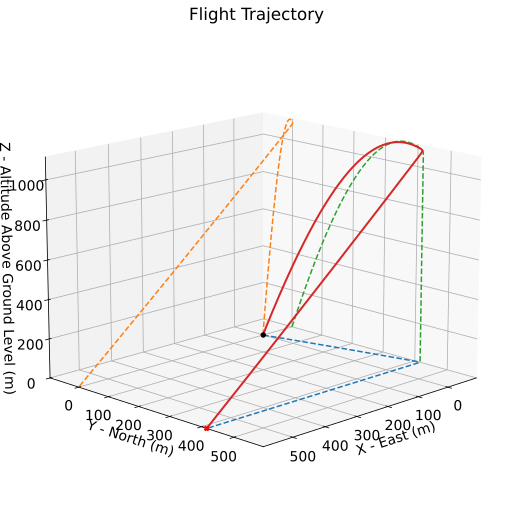



Trajectory Kinematic Plots



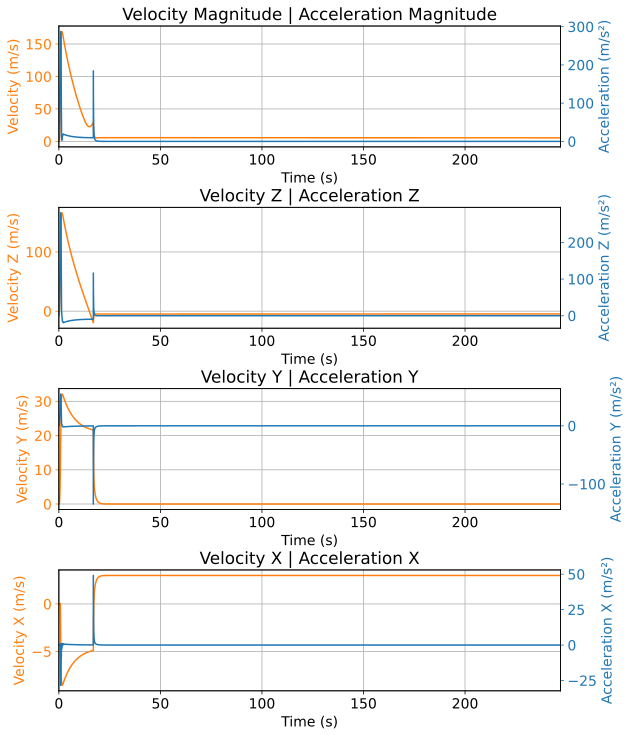



Angular Position Plots



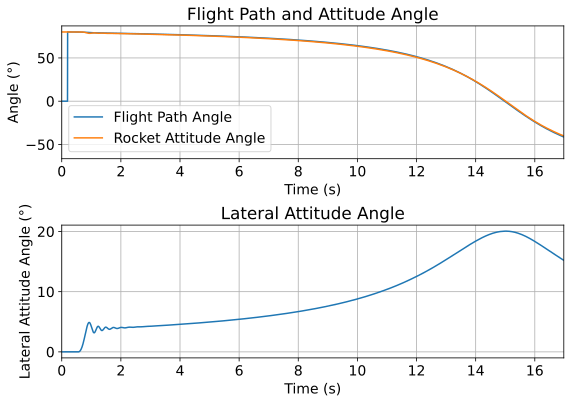



Path, Attitude and Lateral Attitude Angle plots



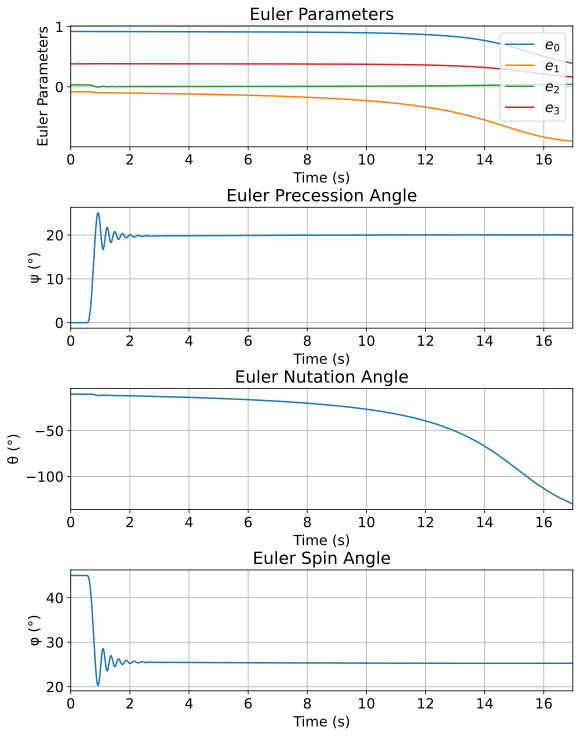



Trajectory Angular Velocity and Acceleration Plots



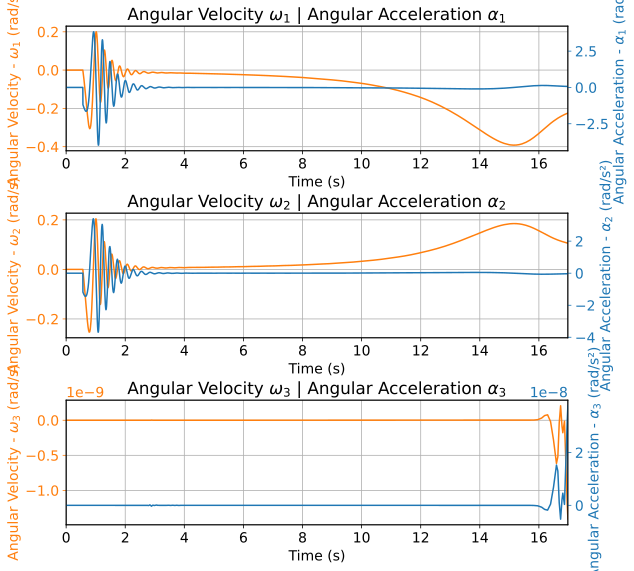



Aerodynamic Forces Plots



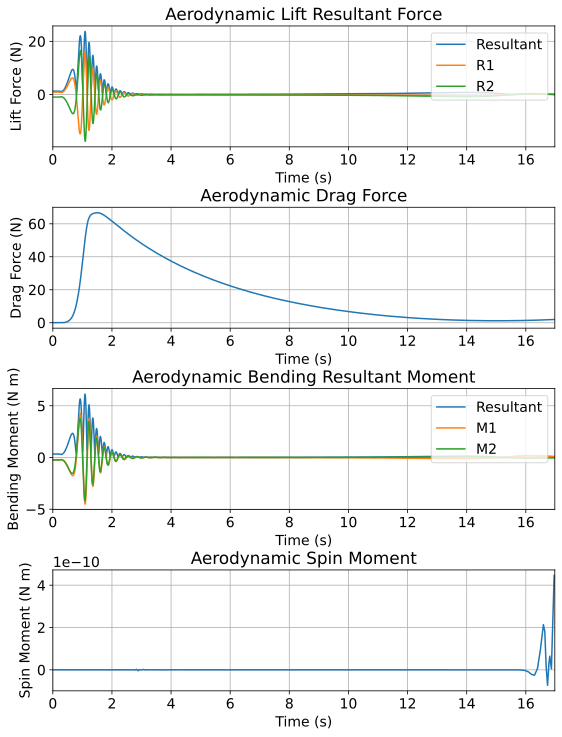



Rail Buttons Forces Plots



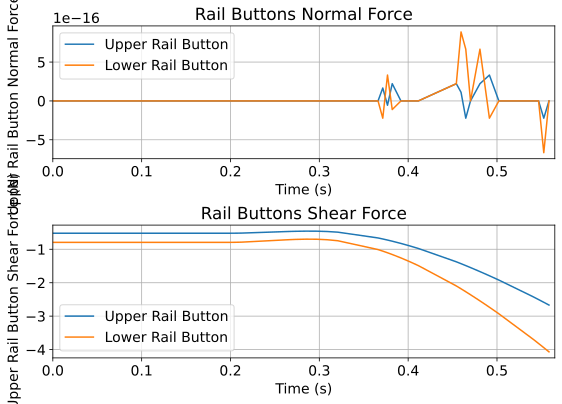



Trajectory Energy Plots



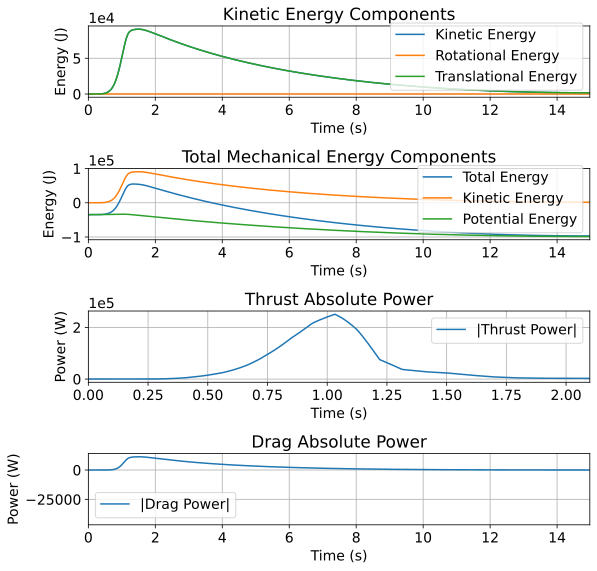



Trajectory Fluid Mechanics Plots



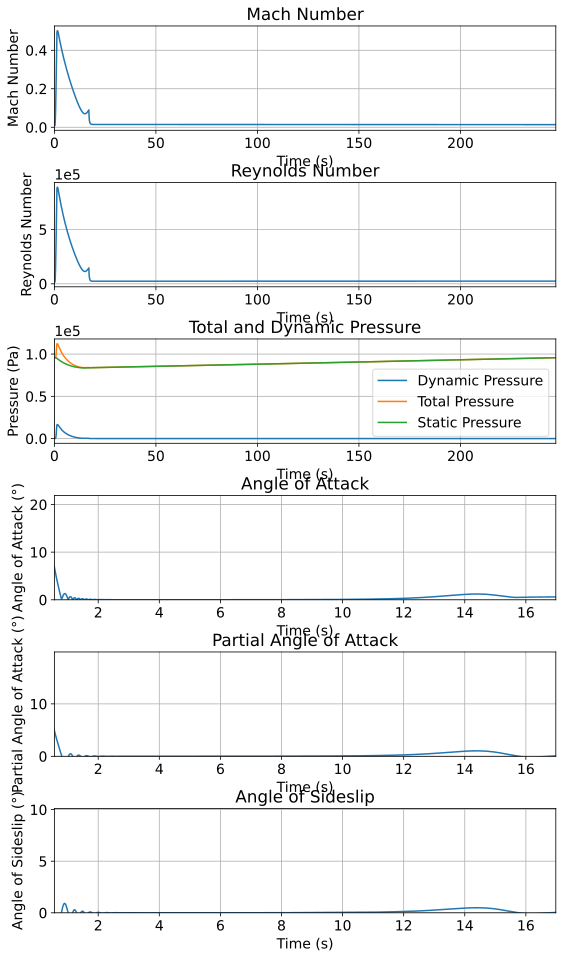



Trajectory Stability and Control Plots



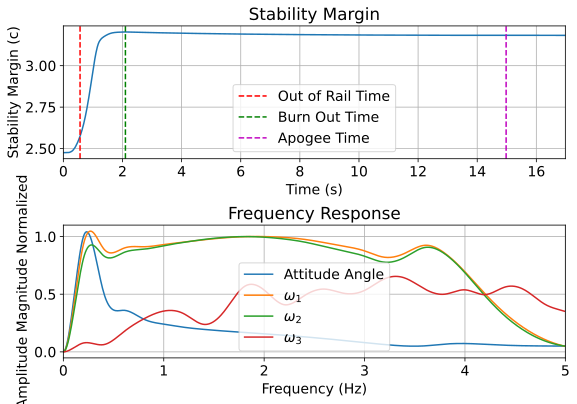



Rocket and Parachute Pressure Plots



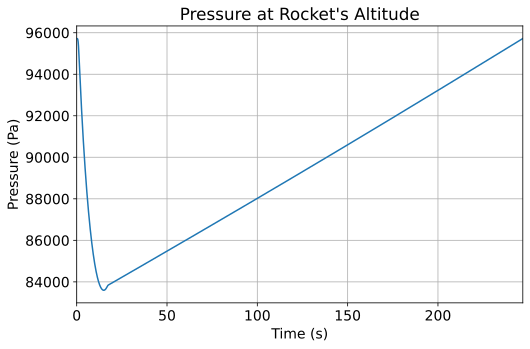


Parachute:  main


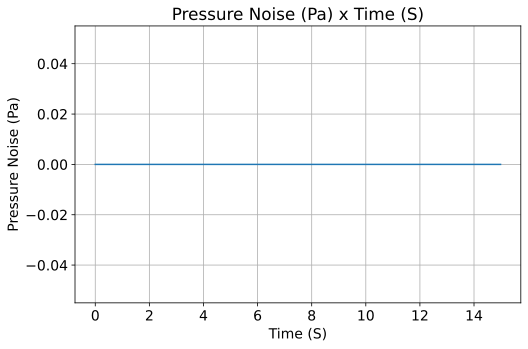

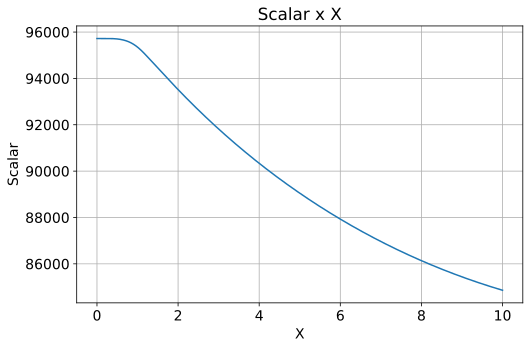

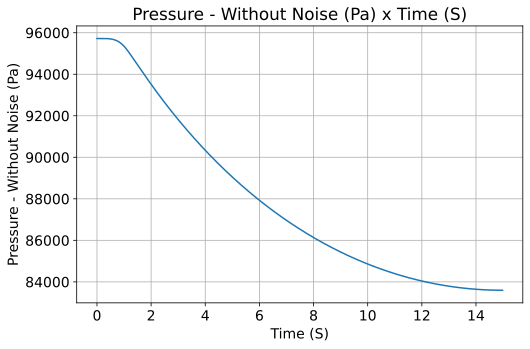

In [21]:
test_flight.all_info()


## Diagnóstico: velocidade de impacto

In [22]:

print("=" * 60)
print("RESUMO DE VOO POR FASES (TRAJETÓRIA DO MERAK)")
print("=" * 60)

print("\n 1. PRE-LAUNCH (Ignição)")
print(f"  Tempo      : 0.00 s")
print(f"  Altitude   : 0.00 m (AGL)")
print(f"  Velocidade : 0.00 m/s")

t_burnout = Motor.burn_out_time
z_burnout = test_flight.z(t_burnout) - env.elevation
v_burnout = test_flight.speed(t_burnout)

print("\n 2. BURNOUT (Fim do propelente)")
print(f"  Tempo      : {t_burnout:.2f} s")
print(f"  Altitude   : {z_burnout:.2f} m (AGL)")
print(f"  Velocidade : {v_burnout:.2f} m/s ({v_burnout*3.6:.2f} km/h)")

t_apogeu = test_flight.apogee_time
z_apogeu = test_flight.apogee - env.elevation
v_apogeu = test_flight.speed(t_apogeu) 

print("\n 3. APOGEE (Altitude Máxima)")
print(f"  Tempo      : {t_apogeu:.2f} s")
print(f"  Altitude   : {z_apogeu:.2f} m (AGL)")
print(f"  Velocidade : {v_apogeu:.2f} m/s (Apenas deslocamento horizontal)")

print("\n 4. PARACHUTE DEPLOYMENT (Abertura do Velame)")
if len(test_flight.parachute_events) == 0:
    print("  Nenhum paraquedas foi acionado!")
else:
    for evento in test_flight.parachute_events:
        t_disparo = evento[0]
        paraquedas = evento[1]
        
        t_abertura = t_disparo + paraquedas.lag
        z_abertura = test_flight.z(t_abertura) - env.elevation
        v_abertura = abs(test_flight.speed(t_abertura))
        
        print(f"  Tempo      : {t_abertura:.2f} s (Inclui {paraquedas.lag}s de lag)")
        print(f"  Altitude   : {z_abertura:.2f} m (AGL)")
        print(f"  Velocidade : {v_abertura:.2f} m/s ({v_abertura*3.6:.2f} km/h) [Em queda livre]")


t_impacto = test_flight.t_final
v_impacto = abs(test_flight.impact_velocity)

print("\n 5. GROUND RECOVERY (Impacto no Solo)")
print(f"  Tempo      : {t_impacto:.2f} s")
print(f"  Altitude   : 0.00 m (AGL)")
print(f"  Velocidade : {v_impacto:.2f} m/s ({v_impacto*3.6:.2f} km/h)")
print("=" * 60)

RESUMO DE VOO POR FASES (TRAJETÓRIA DO MERAK)

 1. PRE-LAUNCH (Ignição)
  Tempo      : 0.00 s
  Altitude   : 0.00 m (AGL)
  Velocidade : 0.00 m/s

 2. BURNOUT (Fim do propelente)
  Tempo      : 2.10 s
  Altitude   : 208.23 m (AGL)
  Velocidade : 161.76 m/s (582.33 km/h)

 3. APOGEE (Altitude Máxima)
  Tempo      : 14.98 s
  Altitude   : 1113.34 m (AGL)
  Velocidade : 22.54 m/s (Apenas deslocamento horizontal)

 4. PARACHUTE DEPLOYMENT (Abertura do Velame)
  Tempo      : 16.98 s (Inclui 2s de lag)
  Altitude   : 1093.82 m (AGL)
  Velocidade : 29.45 m/s (106.01 km/h) [Em queda livre]

 5. GROUND RECOVERY (Impacto no Solo)
  Tempo      : 246.98 s
  Altitude   : 0.00 m (AGL)
  Velocidade : 4.62 m/s (16.63 km/h)


## Simulação de Monte Carlo

CONFIGURANDO SIMULAÇÃO DE MONTE CARLO - MERAK


c:\Users\guilh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\rocketpy\simulation\monte_carlo.py:137: UserWarning: This class is still under testing and some attributes may be changed in next versions
  warnings.warn(


The following input file was imported: monte_carlo\merak_mc.inputs.txt
A total of 300 simulations results were loaded from the following output file: monte_carlo\merak_mc.outputs.txt

The following error file was imported: monte_carlo\merak_mc.errors.txt                                          
Rodando 300 simulações de voo. Isso pode levar alguns segundos...
Starting Monte Carlo analysis                                         
Current iteration: 000300 | Average Time per Iteration: 0.289 s | Estimated time left: 0 s 
Completed 300 iterations. In total, 300 simulations are exported.
Total wall time: 86.8 s 
Results saved to monte_carlo\merak_mc.outputs.txt                                        
Simulação concluída!
Monte Carlo Simulation by RocketPy
Data Source:  monte_carlo\merak_mc
Number of simulations:  300
Results: 

                Parameter            Mean          Median       Std. Dev.    95% PI Lower    95% PI Upper
---------------------------------------------------------

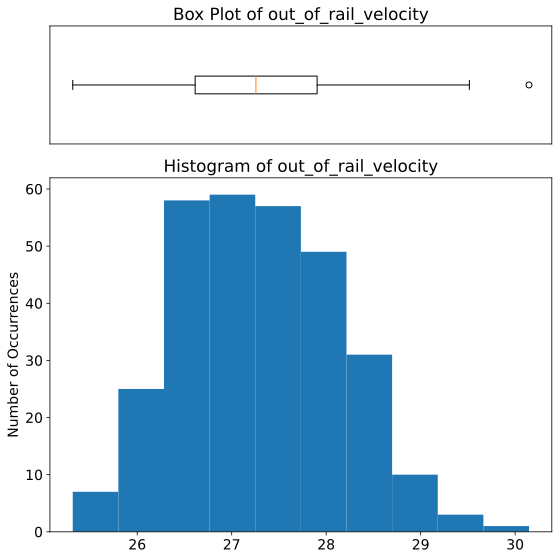

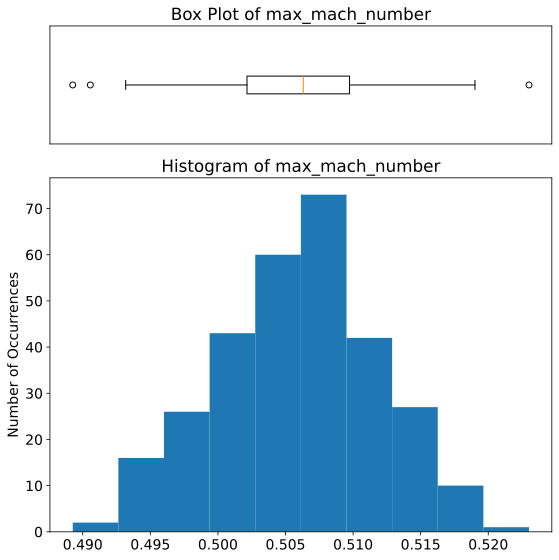

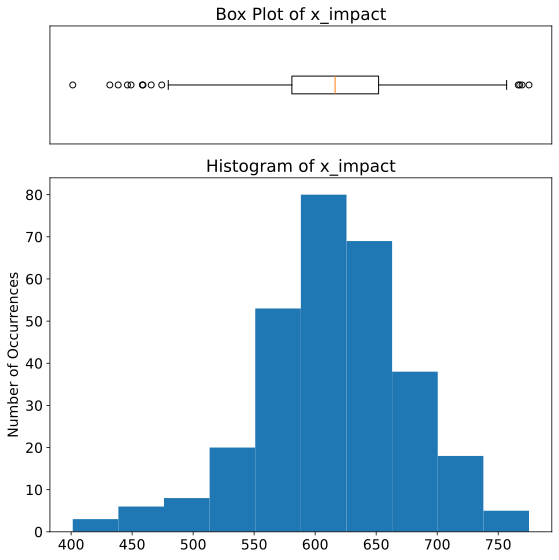

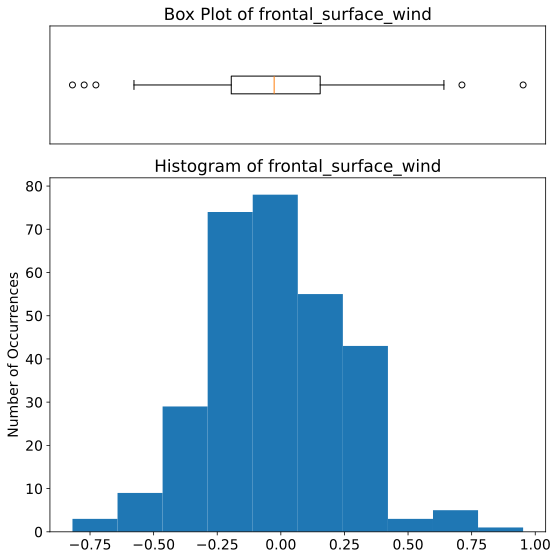

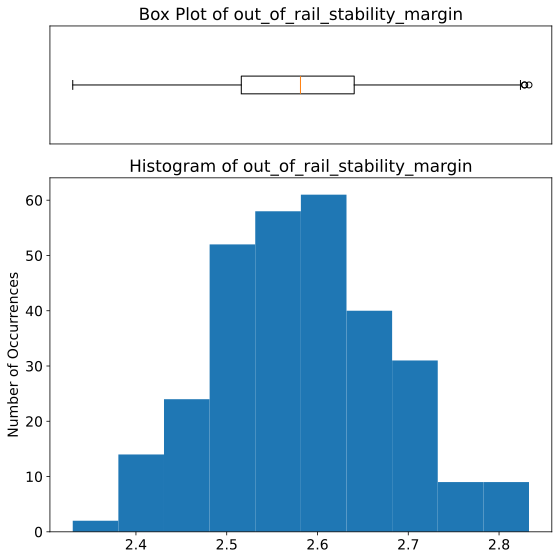

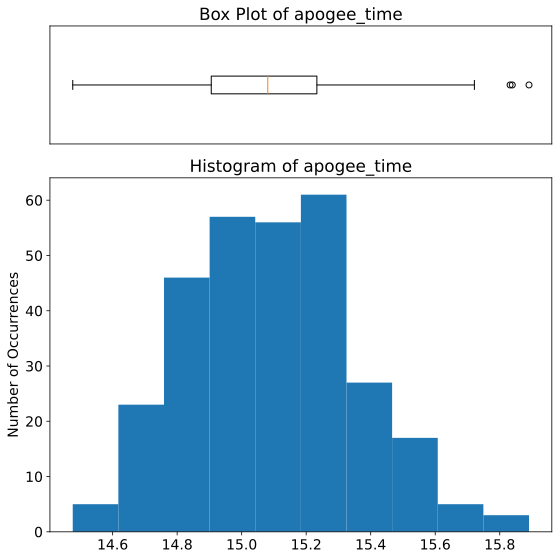

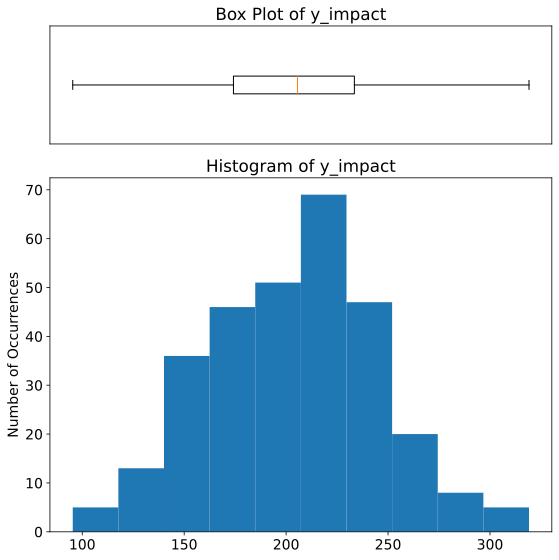

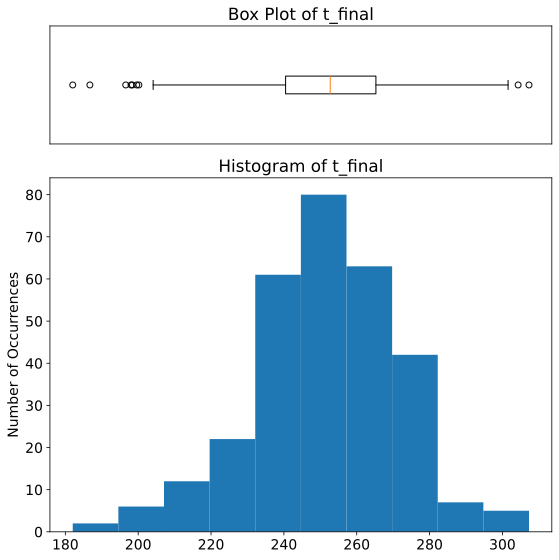

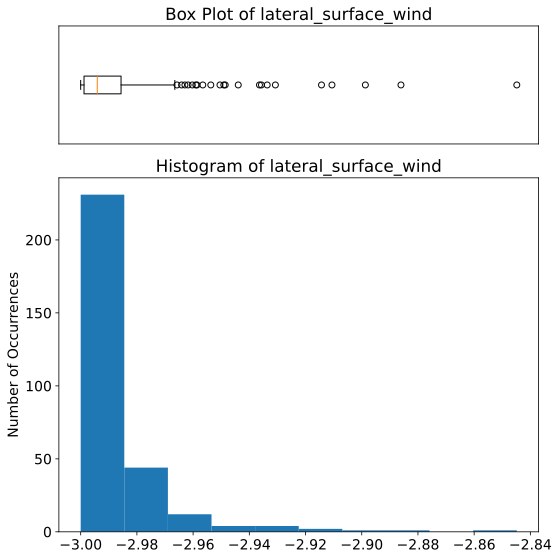

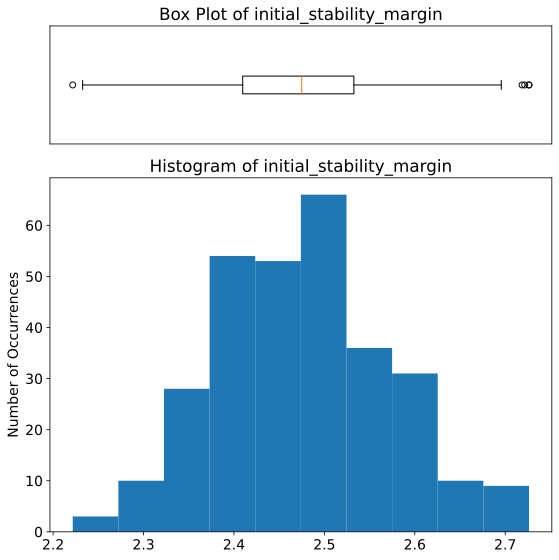

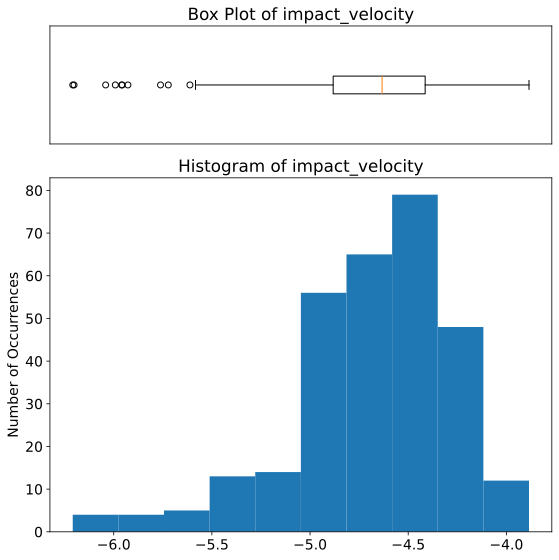

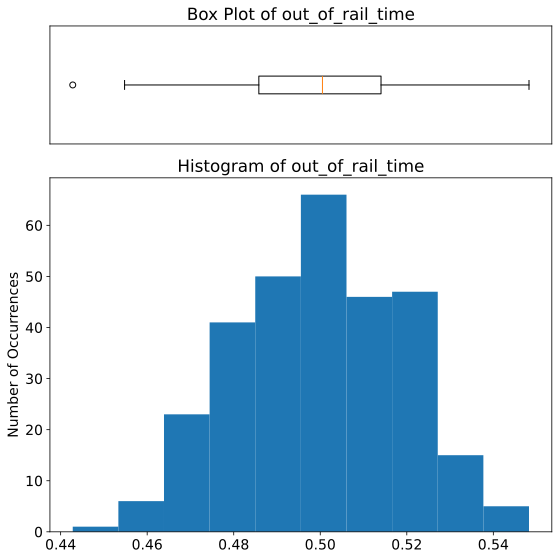

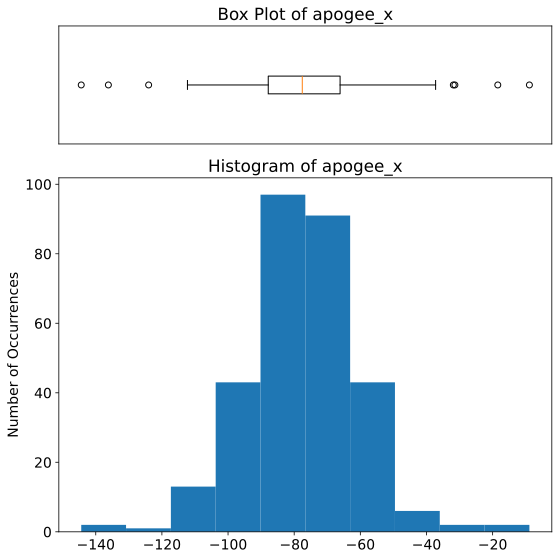

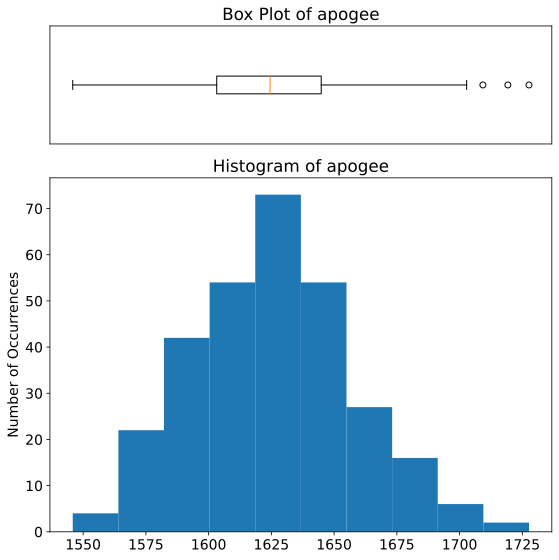

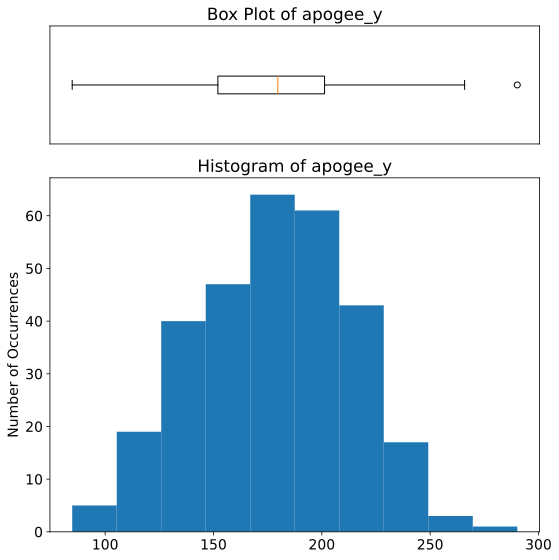

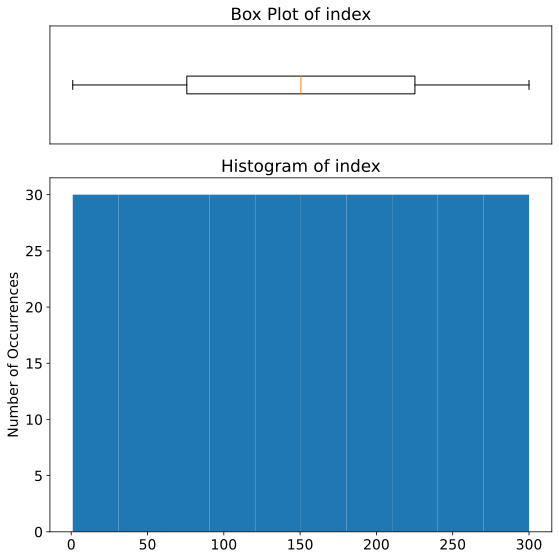

In [23]:
#Os valores de incerteza (dp_) foram inicialmente baseados nas faixas típicas sugeridas pela documentação do RocketPy para simulações de Monte Carlo , consistentes com a prática comum em foguetes amadores. Além de medições reais e diretas de tolerância de fabricação e instrumentação de bancada.
from rocketpy.stochastic import (
    StochasticEnvironment, StochasticFlight, StochasticNoseCone,
    StochasticParachute, StochasticRailButtons, StochasticRocket,
    StochasticSolidMotor, StochasticTail, StochasticTrapezoidalFins
)

print("="*50)
print("CONFIGURANDO SIMULAÇÃO DE MONTE CARLO - MERAK")
print("="*50)



dp_motor_dry_mass     = 0.020          
dp_grain_density      = 20             
dp_nozzle_radius      = 0.5 / 1000     
dp_throat_radius      = 0.5 / 1000     
dp_grain_separation   = 0.5 / 1000     
dp_grain_outer_radius = 0.5 / 1000     
dp_grain_inner_radius = 0.5 / 1000     
dp_grain_height       = 1.0 / 1000     
dp_burn_time          = 0.1            

dp_rocket_mass   = 0.050               
dp_rocket_radius = 0.5 / 1000          
dp_inertia_11    = 0.754 * 0.05
dp_inertia_33    = 0.012 * 0.05
dp_cm_sem_motor  = 0.010               
drag_factor_std  = 0.10                

dp_nose_length    = 0.002              
dp_fin_span       = 0.001              
dp_fin_root_chord = 0.001
dp_fin_tip_chord  = 0.001
dp_tail_length    = 0.001

dp_cd_s_main      = (1.5 * 3.295) * 0.15   
dp_lag_rec        = 0.5                

dp_inclination = 1                     
dp_heading     = 5                     
dp_rail_length = 0.01                  


stoch_env = StochasticEnvironment(environment=env)

stoch_motor = StochasticSolidMotor(
    solid_motor=Motor,
    burn_out_time=(2.0994, dp_burn_time),
    dry_mass=(1.850, dp_motor_dry_mass),
    nozzle_radius=(18.03 / 1000, dp_nozzle_radius),
    throat_radius=(7.5 / 1000, dp_throat_radius),
    grain_density=(1841, dp_grain_density),
    grain_separation=(1 / 1000, dp_grain_separation),
    grain_outer_radius=(28.52 / 1000, dp_grain_outer_radius),
    grain_initial_inner_radius=(17 / 1000, dp_grain_inner_radius),
    grain_initial_height=(70 / 1000, dp_grain_height),
)

stoch_nose = StochasticNoseCone(nosecone=nose_cone, length=(0.16, dp_nose_length))

stoch_fins = StochasticTrapezoidalFins(
    trapezoidal_fins=fin_set,
    span=(0.148, dp_fin_span),
    root_chord=(0.305, dp_fin_root_chord),
    tip_chord=(0.15, dp_fin_tip_chord),
)

stoch_tail = StochasticTail(tail=tail, length=(0.046, dp_tail_length))

stoch_rail_buttons = StochasticRailButtons(
    rail_buttons=rail_buttons, 
    angular_position=(45, 2)
)

stoch_parachute = StochasticParachute(
    parachute=main, 
    cd_s=(1.5 * 3.295, dp_cd_s_main), 
    lag=(2, dp_lag_rec)
)

stoch_rocket = StochasticRocket(
    rocket=merak,
    radius=(0.0802 / 2, dp_rocket_radius),
    mass=(4.457, dp_rocket_mass),
    inertia_11=(0.754, dp_inertia_11),
    inertia_33=(0.012, dp_inertia_33),
    center_of_mass_without_motor=(0.77513, dp_cm_sem_motor),
    power_off_drag_factor=(1.0, drag_factor_std),
    power_on_drag_factor=(1.0, drag_factor_std),
)

stoch_rocket.add_motor(stoch_motor, position=(-ConstanteDeslocamento, 0.001))
stoch_rocket.add_nose(stoch_nose, position=(POS_NOSE, 0.001))
stoch_rocket.add_trapezoidal_fins(stoch_fins, position=(POS_FINS, 0.001))
stoch_rocket.add_tail(stoch_tail, position=(POS_TAIL, 0.001))
stoch_rocket.set_rail_buttons(stoch_rail_buttons, lower_button_position=(POS_RAIL_LOWER, 0.001))
stoch_rocket.add_parachute(stoch_parachute)

stoch_flight = StochasticFlight(
    flight=test_flight,
    inclination=(85, dp_inclination),
    heading=(0, dp_heading),
    rail_length=(4, dp_rail_length),
)
# ----------------------------------------

from rocketpy import MonteCarlo
import os

os.makedirs("monte_carlo", exist_ok=True)

merak_mc = MonteCarlo(
    filename="monte_carlo/merak_mc",
    environment=stoch_env,
    rocket=stoch_rocket,
    flight=stoch_flight,
)

QTD_SIMULACOES = 300

print(f"Rodando {QTD_SIMULACOES} simulações de voo. Isso pode levar alguns segundos...")
merak_mc.simulate(number_of_simulations=QTD_SIMULACOES, append=False)
print("Simulação concluída!")

merak_mc.prints.all()
merak_mc.plots.all()

Total de simulações disponíveis: 300


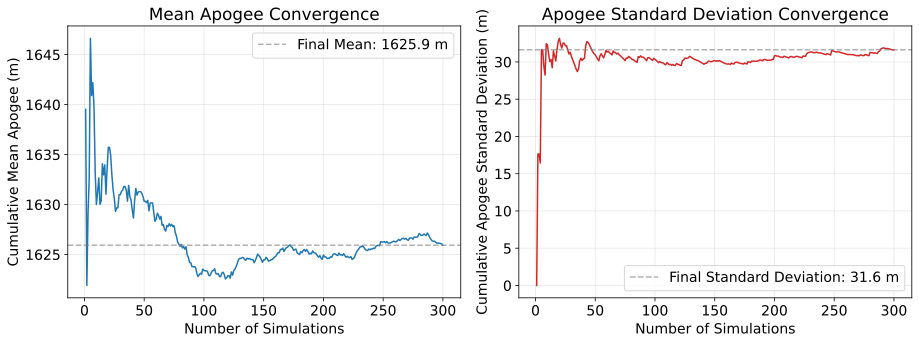


ATENÇÃO: Os valores abaixo representam o apogeu absoluto
em relação ao NÍVEL DO MAR (ASL).
Média do apogeu com 150 simulações : 1624.47 m
Média do apogeu com 300 simulações  : 1625.93 m
Diferença relativa                        : 0.09%

-> Convergência atingida bem antes de 300 simulações (diferença < 1% já com metade dos dados).


In [24]:
import numpy as np
import matplotlib.pyplot as plt

try:
    apogeus = np.array(merak_mc.results["apogee"])
except (AttributeError, KeyError):
    import pandas as pd
    df_resultados = pd.read_csv("monte_carlo/merak_mc.outputs.csv")
    apogeus = df_resultados["apogee"].to_numpy()

try:
    impactos = np.array(merak_mc.results["x_impact"])  
except (AttributeError, KeyError):
    impactos = None

n_total = len(apogeus)
print(f"Total de simulações disponíveis: {n_total}")

def media_desvio_cumulativos(dados):
    medias = np.zeros(len(dados))
    desvios = np.zeros(len(dados))
    for i in range(1, len(dados) + 1):
        medias[i - 1] = np.mean(dados[:i])
        desvios[i - 1] = np.std(dados[:i])
    return medias, desvios

media_apogeu_cumulativa, desvio_apogeu_cumulativo = media_desvio_cumulativos(apogeus)
n_simulacoes = np.arange(1, n_total + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(n_simulacoes, media_apogeu_cumulativa, color="#1f77b4")
ax1.axhline(media_apogeu_cumulativa[-1], color="gray", linestyle="--", alpha=0.6,
            label=f"Final Mean: {media_apogeu_cumulativa[-1]:.1f} m")
ax1.set_xlabel("Number of Simulations")
ax1.set_ylabel("Cumulative Mean Apogee (m)")
ax1.set_title("Mean Apogee Convergence")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(n_simulacoes, desvio_apogeu_cumulativo, color="#d62728")
ax2.axhline(desvio_apogeu_cumulativo[-1], color="gray", linestyle="--", alpha=0.6,
            label=f"Final Standard Deviation: {desvio_apogeu_cumulativo[-1]:.1f} m")
ax2.set_xlabel("Number of Simulations")
ax2.set_ylabel("Cumulative Apogee Standard Deviation (m)")
ax2.set_title("Apogee Standard Deviation Convergence")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("monte_carlo/convergencia_apogeu.png", dpi=300, bbox_inches="tight")
plt.show()

metade = n_total // 2
media_metade = np.mean(apogeus[:metade])
media_final = media_apogeu_cumulativa[-1]
diferenca_percentual = abs(media_final - media_metade) / media_final * 100

print("\n" + "=" * 60)
print(f"ATENÇÃO: Os valores abaixo representam o apogeu absoluto")
print(f"em relação ao NÍVEL DO MAR (ASL).")
print("=" * 60)

print(f"Média do apogeu com {metade} simulações : {media_metade:.2f} m")
print(f"Média do apogeu com {n_total} simulações  : {media_final:.2f} m")
print(f"Diferença relativa                        : {diferenca_percentual:.2f}%")

if diferenca_percentual < 1.0:
    print(f"\n-> Convergência atingida bem antes de {n_total} simulações "
          f"(diferença < 1% já com metade dos dados).")
else:
    print(f"\n-> A média ainda está mudando de forma perceptível. "
          f"Considere rodar mais simulações do que {n_total}.")

Monte Carlo Simulation by RocketPy
Data Source:  monte_carlo\merak_mc
Number of simulations:  300
Results: 

                Parameter            Mean          Median       Std. Dev.    95% PI Lower    95% PI Upper
--------------------------------------------------------------------------------------------------------------
     out_of_rail_velocity          27.291          27.256           0.844          25.828          28.918
          max_mach_number           0.506           0.506           0.006           0.495           0.517
                 x_impact         615.049         616.332          62.195         469.717         726.296
     frontal_surface_wind          -0.019          -0.026           0.262          -0.502           0.470
out_of_rail_stability_margin           2.584           2.581           0.095           2.417           2.789
              apogee_time          15.089          15.081           0.253          14.652          15.615
                 y_impact         2

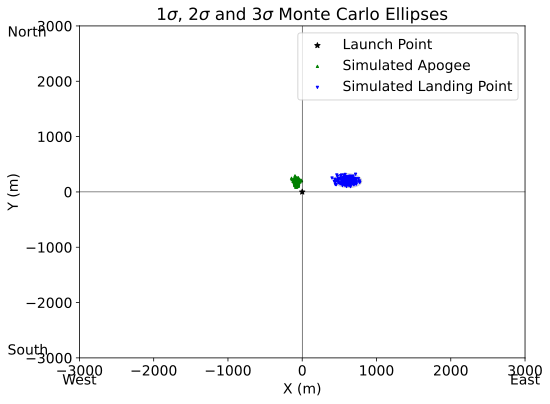

In [25]:


merak_mc.prints.all()
merak_mc.plots.ellipses()


In [26]:
import pandas as pd

df = pd.DataFrame({
    "t": test_flight.time,
    "x": [test_flight.x(t) for t in test_flight.time],
    "y": [test_flight.y(t) for t in test_flight.time],
    "z": [test_flight.z(t) for t in test_flight.time],
    "vx": [test_flight.vx(t) for t in test_flight.time],
    "vy": [test_flight.vy(t) for t in test_flight.time],
    "vz": [test_flight.vz(t) for t in test_flight.time],
    "latitude": [test_flight.latitude(t) for t in test_flight.time],
    "longitude": [test_flight.longitude(t) for t in test_flight.time],
    "altitude": [test_flight.altitude(t) for t in test_flight.time],
})
df.to_csv("meu_voo.csv", index=False)